# Supplementary Figure S10a. Reactome enrichment of glycoproteins colocalized with excitatory-neuron / astrocyte events

Over-representation analysis (ConsensusPathDB-style ORA output, `ORA_results_glyco_enrichment.tab`) of glycoproteins whose *trans*-glycoprotein QTL colocalized with excitatory-neuron initiating / astrocyte recipient events. Shown are all Reactome pathways with q-value (FDR) < 0.01 (12 pathways), ordered by P value; point size is the number of input glycoproteins in the pathway. The input gene list and background were defined upstream of the source notebook and are not reconstructed here. Some long Reactome names are shortened for display (`pathway` keeps the original name).

Input: `data/Figure_S10a_glycoprotein_reactome.rds`

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_S10a_glycoprotein_reactome.rds")
res[, c("pathway_label", "p_value", "fdr", "overlap_count", "overlap_genes")]

pathway_label,p_value,fdr,overlap_count,overlap_genes
<chr>,<dbl>,<dbl>,<int>,<chr>
Neurofascin interactions,6.140371e-07,0.0000380703,3,CNTNAP1; NRCAM; NFASC
L1CAM interactions,7.149318e-06,0.0002216289,5,CNTN2; NRCAM; NFASC; L1CAM; CNTNAP1
Neutrophil degranulation,3.427403e-05,0.0007083300,8,SERPINA3; GPI; ADAM10; NFASC; GAA; TMEM30A; PPIA; ASAH1
L1-ankyrin interactions,6.155861e-05,0.0009541584,3,NRCAM; NFASC; L1CAM
Carbohydrate metabolism,9.670464e-05,0.0010587638,6,DCN; GPI; ACAN; PRELP; NUP210; GAA
Extracellular matrix organization,1.024610e-04,0.0010587638,6,DCN; TNR; ACAN; COL14A1; ADAM10; COL6A3
NrCAM interactions,1.453936e-04,0.0012320483,2,CNTN2; NRCAM
Extracellular matrix degradation,1.589740e-04,0.0012320483,4,DCN; ADAM10; COL14A1; ACAN
Axon guidance,3.300527e-04,0.0022736964,6,CNTN2; NRCAM; CNTNAP1; NFASC; L1CAM; COL6A3


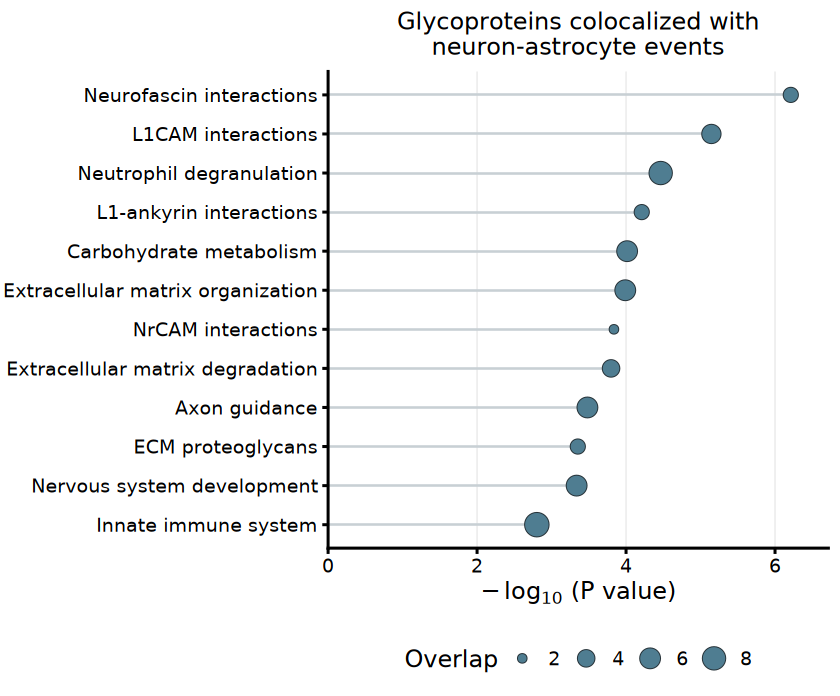

In [2]:
res$neglog10_p <- -log10(res$p_value)
res$pathway_label <- factor(res$pathway_label, levels = rev(res$pathway_label))

p <- ggplot(res, aes(y = pathway_label)) +
  geom_segment(aes(x = 0, xend = neglog10_p, yend = pathway_label),
               colour = "#C8D0D4", linewidth = 0.55) +
  geom_point(aes(x = neglog10_p, size = overlap_count), shape = 21,
             fill = "#4F7D91", colour = "#263238", stroke = 0.32) +
  scale_size_continuous(range = c(2.2, 6.4), breaks = c(2, 4, 6, 8), limits = c(2, 9),
                        name = "Overlap") +
  scale_x_continuous(limits = c(0, max(res$neglog10_p) * 1.06),
                     expand = expansion(mult = c(0, 0.02))) +
  labs(x = expression(-log[10] ~ "(P value)"), y = NULL,
       title = "Glycoproteins colocalized with
neuron-astrocyte events") +
  theme_classic(base_size = 14) +
  theme(plot.title = element_text(hjust = 0.5, size = 14),
        panel.grid.major.x = element_line(colour = "#E8E8E8", linewidth = 0.28),
        legend.position = "bottom")

options(repr.plot.width = 7, repr.plot.height = 5.8)
p